<a href="https://colab.research.google.com/github/ggalarza1/Bitcoin_Monte_Carlo/blob/main/Bitcoin_Monte_Carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Bitcoin Price Simulation (Monte Carlo Simulation until 12/31/2026)
Here we fetch historical data for Bitcoin (`BTCUSD`) and run our Monte Carlo simulation to project daily price paths up until December 31, 2026.

In [ ]:
import numpy as np
import pandas as pd
import os
import datetime as dt
import pytz

class MCSimulation:
    """
    A Python class for running Monte Carlo simulation on portfolio price data.
    """
    def __init__(self, portfolio_data, weights="", num_simulation=1000, num_trading_days=252):
        if not isinstance(portfolio_data, pd.DataFrame):
            raise TypeError("portfolio_data must be a Pandas DataFrame")

        if weights == "":
            num_stocks = len(portfolio_data.columns.get_level_values(0).unique())
            weights = [1.0/num_stocks for s in range(0,num_stocks)]
        else:
            if round(sum(weights),2) < .99:
                raise AttributeError("Sum of portfolio weights must equal one.")

        if not "daily_return" in portfolio_data.columns.get_level_values(1).unique():
            close_df = portfolio_data.xs('close',level=1,axis=1).pct_change()
            tickers = portfolio_data.columns.get_level_values(0).unique()
            column_names = [(x,"daily_return") for x in tickers]
            close_df.columns = pd.MultiIndex.from_tuples(column_names)
            portfolio_data = portfolio_data.merge(close_df,left_index=True,right_index=True).reindex(columns=tickers,level=0)

        self.portfolio_data = portfolio_data
        self.weights = weights
        self.nSim = num_simulation
        self.nTrading = num_trading_days
        self.simulated_return = ""

    def calc_cumulative_return(self):
        # Get closing prices of each stock
        last_prices = self.portfolio_data.xs('close',level=1,axis=1)[-1:].values.tolist()[0]

        # Calculate the mean and standard deviation of daily returns for each stock
        daily_returns = self.portfolio_data.xs('daily_return',level=1,axis=1)
        mean_returns = daily_returns.mean().tolist()
        std_returns = daily_returns.std().tolist()

        # Initialize an empty dictionary to collect cumulative returns per simulation run
        portfolio_cumulative_returns_dict = {}

        # Run the simulation of projecting stock prices 'nSim' number of times
        for n in range(self.nSim):

            if n % 100 == 0:
                print(f"Running Monte Carlo simulation number {n}.")

            # Create a list of lists to contain the simulated values for each stock
            simvals = [[p] for p in last_prices]

            # For each stock in our data:
            for s in range(len(last_prices)):
                for i in range(self.nTrading):
                    simvals[s].append(simvals[s][-1] * (1 + np.random.normal(mean_returns[s], std_returns[s])))

            # Calculate the daily returns of simulated prices
            sim_df = pd.DataFrame(simvals).T.pct_change()

            # Use the `dot` function with the weights to multiply weights
            sim_df = sim_df.dot(self.weights)

            # Store the series in our dictionary to avoid calling frame.insert repeatedly
            portfolio_cumulative_returns_dict[n] = (1 + sim_df.fillna(0)).cumprod()

        # Combine all columns at once using pandas constructor, and then explicitly copy to de-fragment
        portfolio_cumulative_returns = pd.DataFrame(portfolio_cumulative_returns_dict).copy()

        # Set attribute to use in plotting
        self.simulated_return = portfolio_cumulative_returns

        # Calculate 95% confidence intervals for final cumulative returns
        self.confidence_interval = portfolio_cumulative_returns.iloc[-1, :].quantile(q=[0.025, 0.975])

        return portfolio_cumulative_returns

    def plot_simulation(self):
        if not isinstance(self.simulated_return,pd.DataFrame):
            self.calc_cumulative_return()
        plot_title = f"{self.nSim} Simulations of Cumulative Portfolio Return Trajectories Over the Next {self.nTrading} Trading Days."
        return self.simulated_return.plot(legend=None,title=plot_title)

    def plot_distribution(self):
        if not isinstance(self.simulated_return,pd.DataFrame):
            self.calc_cumulative_return()
        plot_title = f"Distribution of Final Cumulative Returns Across All {self.nSim} Simulations"
        plt = self.simulated_return.iloc[-1, :].plot(kind='hist', bins=10,density=True,title=plot_title)
        plt.axvline(self.confidence_interval.iloc[0], color='r')
        plt.axvline(self.confidence_interval.iloc[1], color='r')
        return plt

    def summarize_cumulative_return(self):
        if not isinstance(self.simulated_return,pd.DataFrame):
            self.calc_cumulative_return()
        metrics = self.simulated_return.iloc[-1].describe()
        ci_series = self.confidence_interval.copy()
        ci_series.index = ["95% CI Lower","95% CI Upper"]
        return pd.concat([metrics, ci_series])

In [ ]:
!pip install -q yfinance
import pandas as pd
import yfinance as yf

# Set start date
start_date_btc = "2021-01-01"

# Dynamically set end date to today's date (exclusive for yfinance, so we grab data up to today)
end_date_btc = pd.Timestamp.now(tz="America/New_York").strftime("%Y-%m-%d")

# Fetch historical Bitcoin data using yfinance
ticker = "BTC-USD"
btc_raw = yf.download(ticker, start=start_date_btc, end=end_date_btc, interval="1d")

# Clean column names to match expected lowercase format ('open', 'high', 'low', 'close', 'volume')
btc_raw = btc_raw[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
btc_raw.columns = ['open', 'high', 'low', 'close', 'volume']

# Format the DataFrame to have a MultiIndex with ticker "BTCUSD" at the top level
btc_raw.columns = pd.MultiIndex.from_product([["BTCUSD"], btc_raw.columns])
btc_df = btc_raw

display(btc_df.tail())

/tmp/ipykernel_1234/2318774788.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  btc_raw = yf.download(ticker, start=start_date_btc, end=end_date_btc, interval="1d")
[*********************100%***********************]  1 of 1 completed


BTCUSD                                            \
                    open          high           low         close   
Date                                                                 
2026-11-11  73720.117188  74703.453125  73141.531250  73964.468750   
2026-11-12  73964.468750  74115.218750  71084.054688  71342.968750   
2026-11-13  71342.968750  71428.531250  67653.070312  68249.273438   
2026-11-14  68249.273438  68377.539062  63329.429688  64128.050781   
2026-11-15  64128.050781  66055.101562  62017.882812  65305.062500   

                         
                 volume  
Date                     
2026-11-11  23451242490  
2026-11-12  27507388119  
2026-11-13  42985296506  
2026-11-14  44019244180  
2026-11-15  39757267458

In [ ]:
# Calculate remaining trading (calendar) days from today until 12/31/2026.
today = pd.Timestamp.now(tz="America/New_York")
target_date = pd.Timestamp("2026-12-31", tz="America/New_York")

sim_days = (target_date - today).days
print(f"Number of simulation days from today ({today.strftime('%Y-%m-%d')}) until 12/31/2026: {sim_days} days")

Number of simulation days from today (2026-11-16) until 12/31/2026: 44 days


In [ ]:
# Configure and run the Monte Carlo Simulation for Bitcoin
MC_btc = MCSimulation(
    portfolio_data = btc_df,
    weights = [1.0],
    num_simulation = 1000,
    num_trading_days = sim_days
)

# Run the simulation
MC_btc.calc_cumulative_return()

Running Monte Carlo simulation number 0.
Running Monte Carlo simulation number 100.
Running Monte Carlo simulation number 200.
Running Monte Carlo simulation number 300.
Running Monte Carlo simulation number 400.
Running Monte Carlo simulation number 500.
Running Monte Carlo simulation number 600.
Running Monte Carlo simulation number 700.
Running Monte Carlo simulation number 800.
Running Monte Carlo simulation number 900.


,0,1,2,3,4,5,6,7,8,9,...,990,991,992,993,994,995,996,997,998,999
0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,1.026603,1.004368,0.911776,0.965794,0.990509,0.994110,1.022513,0.992929,1.039850,1.020475,...,1.008131,1.029614,0.996344,1.015051,1.003351,0.994144,0.943868,0.984822,0.943363,0.956425
2,1.028593,1.036226,0.897503,0.993870,1.043628,0.984007,1.054080,1.007394,1.051059,0.985870,...,0.990604,1.013968,1.031568,1.031117,0.989364,1.024236,0.927983,1.024612,0.924162,0.996975
3,0.998967,1.066019,0.928513,0.981305,1.055336,0.946236,1.023031,1.006043,1.018641,0.978756,...,1.034102,0.968840,0.999171,1.037257,1.068356,1.038071,0.888770,1.017384,0.951205,0.981102
4,1.016112,1.083722,0.923680,0.965063,1.037515,0.930473,1.053688,0.979636,1.099967,1.012723,...,1.072163,1.007842,0.995356,1.064130,1.116611,0.981862,0.878389,1.007804,0.953699,0.965677
5,1.002048,1.040710,0.953692,0.959709,1.054059,0.868431,1.058048,0.978048,1.102935,1.023622,...,0.985178,1.023197,0.999121,1.058256,1.123689,0.986984,0.899724,1.009375,0.937284,0.944823
6,0.987489,1.008719,0.921208,0.934400,1.008524,0.899620,1.039213,0.980124,1.153532,1.018260,...,1.013351,0.997267,1.021582,1.032967,1.129458,1.006072,0.874630,0.952159,0.990101,0.928511
7,1.028291,0.989787,0.892369,0.912051,0.982998,0.914457,1.081412,0.937057,1.131155,1.019846,...,1.035824,0.990026,0.978256,1.054636,1.138192,0.945569,0.908376,0.976650,0.985958,0.975861
8,1.033866,0.998299,0.890487,0.924723,0.971082,0.931718,1.184120,0.935352,1.121029,1.003670,...,1.029860,0.975485,1.000869,1.033300,1.158132,0.971024,0.904813,0.924646,0.989723,0.963964
9,1.030721,1.044372,0.880073,0.943298,1.020947,0.934829,1.170517,0.925925,1.145244,1.010092,...,1.013386,0.976400,1.024575,1.028605,1.146876,0.973642,0.909651,0.914128,1.026396,0.917546


<Axes: title={'center': '1000 Simulations of Cumulative Portfolio Return Trajectories Over the Next 44 Trading Days.'}>

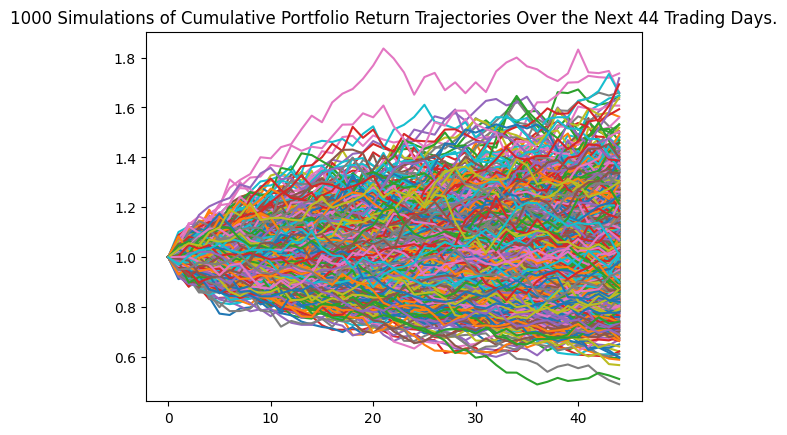

In [ ]:
# Plot the simulated trajectories for Bitcoin
# Note: Make sure cell 43283a95 runs successfully to completion before running this plot
MC_btc.plot_simulation()

<Axes: title={'center': 'Distribution of Final Cumuluative Returns Across All 1000 Simulations'}, ylabel='Frequency'>

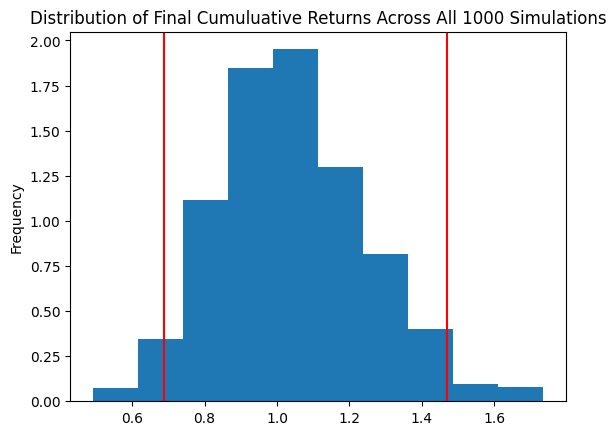

In [ ]:
# Plot the distribution of simulated ending prices on 12/31/2026
MC_btc.plot_distribution()

In [ ]:
# Get final summary statistics for Bitcoin cumulative return using pandas 2.0+ compatible syntax
import pandas as pd
import types

def patch_summarize_cumulative_return(self):
    if not isinstance(self.simulated_return, pd.DataFrame):
        self.calc_cumulative_return()
    metrics = self.simulated_return.iloc[-1].describe()
    ci_series = self.confidence_interval.copy()
    ci_series.index = ["95% CI Lower", "95% CI Upper"]
    return pd.concat([metrics, ci_series])

# Apply patch
MC_btc.summarize_cumulative_return = types.MethodType(patch_summarize_cumulative_return, MC_btc)

# Retrieve summary statistics
btc_summary = MC_btc.summarize_cumulative_return()

last_btc_price = btc_df["BTCUSD"]["close"].dropna().iloc[-1]
low_proj = round(btc_summary["95% CI Lower"] * last_btc_price, 2)
high_proj = round(btc_summary["95% CI Upper"] * last_btc_price, 2)

print(f"Latest Bitcoin price: ${last_btc_price:,.2f}")
print(f"There is a 95% confidence that the price of Bitcoin will end between ${low_proj:,.2f} and ${high_proj:,.2f} by 12/31/2026.")

Latest Bitcoin price: $65,305.06
There is a 95% confidence that the price of Bitcoin will end between $45,866.63 and $95,293.65 by 12/31/2026.


In [ ]:
# Fetch summary statistics from the Bitcoin Monte Carlo simulation results
btc_tbl = MC_btc.summarize_cumulative_return()

# Print summary statistics
print(btc_tbl)

count           1000.000000
mean               1.034743
std                0.201155
min                0.574440
25%                0.888117
50%                1.015739
75%                1.167011
max                1.903270
95% CI Lower       0.702344
95% CI Upper       1.459208
Name: 44, dtype: float64


In [ ]:
# Translate cumulative return summary statistics into actual projected Bitcoin prices
btc_price_tbl = btc_tbl * last_btc_price

# Count should remain a count of simulations, not multiplied by price
btc_price_tbl["count"] = btc_tbl["count"]

# Format and display the statistics in USD
pd.options.display.float_format = '${:,.2f}'.format
print("Projected Bitcoin Price Summary Statistics (Ending 12/31/2026):")
display(btc_price_tbl)

Projected Bitcoin Price Summary Statistics (Ending 12/31/2026):


,44
count,"$1,000.00"
mean,"$67,573.93"
std,"$13,136.45"
min,"$37,513.85"
25%,"$57,998.57"
50%,"$66,332.92"
75%,"$76,211.72"
max,"$124,293.19"
95% CI Lower,"$45,866.63"
95% CI Upper,"$95,293.65"
